# Machine Learning ki Pehli Class: Linear Regression 🏠

**AI for Everyone** | Instructor: Mian Muhammad Azam Ayaz

Is notebook mein hum teen cheezein seekhenge, step by step:

1. **Machine Learning** kya hoti hai
2. **Supervised Learning** kya hoti hai
3. **Linear Regression** kya hai, aur usko Python mein kaise use karte hain

Dataset: `Housing.csv` (545 gharon ka data, unki price aur features ke sath)

> **Kaise chalana hai:** Har cell ko upar se neeche order mein run karo. Cell select karo aur `Shift + Enter` dabao.

---
## Part 1: Machine Learning kya hai? 🤖

**Simple definition:** Machine Learning (ML) aisi technique hai jisme computer ko hum rules khud nahi likh kar dete, balkay usay **data aur examples** dete hain, aur computer khud un examples se **pattern seekh** leta hai.

### Normal programming vs Machine Learning

| Normal Programming | Machine Learning |
|---|---|
| Hum rules likhte hain | Computer data se rules seekhta hai |
| Input + Rules ➜ Output | Input + Output ➜ Rules (Model) |
| Example: `if area > 5000: price = high` | Example: 500 gharon ka data do, model khud samajh le ga price kaise banti hai |

### Real life example
Socho ek property dealer 20 saal se kaam kar raha hai. Ghar dekhte hi bata deta hai "ye 50 lakh ka hai". Usne koi formula ratta nahi lagaya, bas **hazaron ghar dekh dekh kar experience** se seekha. Machine Learning bhi bilkul yahi karti hai, bas experience ki jagah **data** hota hai.

### ML ki 3 main types
- **Supervised Learning:** Data ke sath sahi jawab (label) bhi diya hota hai ✅ *(aaj ka topic)*
- **Unsupervised Learning:** Sirf data hota hai, jawab nahi. Model khud groups dhoondta hai (jaise customers ko groups mein baantna)
- **Reinforcement Learning:** Model try karta hai, reward ya punishment milti hai, aur aese seekhta hai (jaise game khelne wala AI)

---
## Part 2: Supervised Learning kya hai? 👨‍🏫

**Definition:** Supervised Learning mein hum model ko aisa data dete hain jisme **input (features)** ke sath **sahi output (label/target)** bhi likha hota hai. Model in examples se seekhta hai, aur phir naye data ka output predict karta hai.

Isko "supervised" isliay kehte hain kyunke jaise teacher bachay ko sawal ke sath sahi jawab bhi batata hai, waise hi hum model ko sahi jawab dikha kar sikhate hain.

### Do important words
- **Features (X):** Wo cheezein jo hum model ko input dete hain. Hamare data mein: area, bedrooms, bathrooms, parking waghaira
- **Target / Label (y):** Wo cheez jo hum predict karna chahte hain. Hamare data mein: **price**

### Supervised Learning ki 2 types

| Type | Output kaisa hota hai | Example |
|---|---|---|
| **Regression** | Number (continuous value) | Ghar ki price, kal ka temperature, salary |
| **Classification** | Category (class) | Email spam hai ya nahi, picture mein cat hai ya dog |

Hamein ghar ki **price** predict karni hai, jo ek number hai. Isliay ye **Regression** problem hai. 🎯

---
## Part 3: Linear Regression kya hai? 📈

**Definition:** Linear Regression sab se simple aur sab se famous regression algorithm hai. Ye data ke beech mein ek **seedhi line (straight line)** fit karta hai, jo input aur output ka relation best tareeqe se dikhati hai. Phir isi line ki madad se naye input ka output predict karta hai.

### Formula (school wala y = mx + c yaad hai? 😄)

$$ y = m \cdot x + c $$

- **y** = jo predict karna hai (price)
- **x** = input feature (area)
- **m** = slope / coefficient. Matlab x ek unit barhe to y kitna barhta hai
- **c** = intercept. Jab x zero ho to y ki value

### Simple vs Multiple Linear Regression
- **Simple Linear Regression:** Sirf **ek** feature (jaise sirf area se price)
- **Multiple Linear Regression:** **Kai** features ek sath (area, bedrooms, bathrooms, AC sab mila kar price)

$$ price = m_1 \cdot area + m_2 \cdot bedrooms + m_3 \cdot bathrooms + ... + c $$

### Model "best line" kaise dhoondta hai?
Har ghar ke liay model ek prediction karta hai. Actual price aur predicted price ke farq ko **error** kehte hain. Model aisi line dhoondta hai jisme sab errors ka total (square kar ke) **sab se kam** ho. Is method ko **Least Squares** kehte hain.

Ab theory kaafi ho gayi, chalo code karte hain! 💻

---
## Step 1: Libraries import karna 📦

Library matlab pehle se bana hua code jo hum use kar sakte hain. Hamein ye chahiye:

- **pandas:** Data ko table (DataFrame) ki shakal mein load aur handle karne ke liay
- **numpy:** Numbers aur math ke kaam ke liay
- **matplotlib / seaborn:** Graphs aur charts banane ke liay
- **scikit-learn (sklearn):** Machine Learning ki main library. Linear Regression isi mein hai

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Graphs thore saaf nazar aayein
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Sab libraries load ho gayin ✅")

Sab libraries load ho gayin ✅


---
## Step 2: Dataset load karna 📂

`pd.read_csv()` CSV file ko parh kar ek table bana deta hai jisko **DataFrame** kehte hain.

> **Google Colab use kar rahe ho?** Neeche wale cell mein upload wali lines ke aage se `#` hata do, run karo, aur `Housing.csv` select kar lo. Agar Jupyter use kar rahe ho to bas CSV ko notebook wale folder mein rakh do.

In [2]:
# Sirf Google Colab ke liay (zaroorat ho to # hata do):
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("Housing.csv")

# Pehli 5 rows dekhte hain
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Har **row** ek ghar hai aur har **column** us ghar ki ek property:

- `price`: Ghar ki qeemat (ye hamara **target y** hai)
- `area`: Ghar ka area (square feet)
- `bedrooms`, `bathrooms`, `stories`: Kamray, washrooms, aur manzilein
- `mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`: yes/no wale columns
- `parking`: Kitni gaariyan park ho sakti hain
- `furnishingstatus`: furnished, semi-furnished, ya unfurnished

---
## Step 3: Data ko samajhna (Exploration) 🔍

Model banane se pehle data ko achi tarah dekhna bohat zaroori hai. Ganda data = ganda model.

`shape` batata hai kitni rows aur columns hain.

In [3]:
print("Rows (gharon ki tadaad):", df.shape[0])
print("Columns (features):", df.shape[1])

Rows (gharon ki tadaad): 545
Columns (features): 13


`info()` har column ka **data type** batata hai. `int64` matlab number, aur `object` matlab text.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


`isnull().sum()` check karta hai kisi column mein **khali values (missing data)** to nahi. Sab zero hain to data saaf hai. 👍

In [5]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

`describe()` number wale columns ki summary deta hai: average (`mean`), sab se kam (`min`), sab se zyada (`max`) waghaira.

In [6]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


---
## Step 4: Data ko graph mein dekhna 📊

Pehle dekhte hain ke **area** aur **price** ka koi relation hai ya nahi. Har dot ek ghar hai.

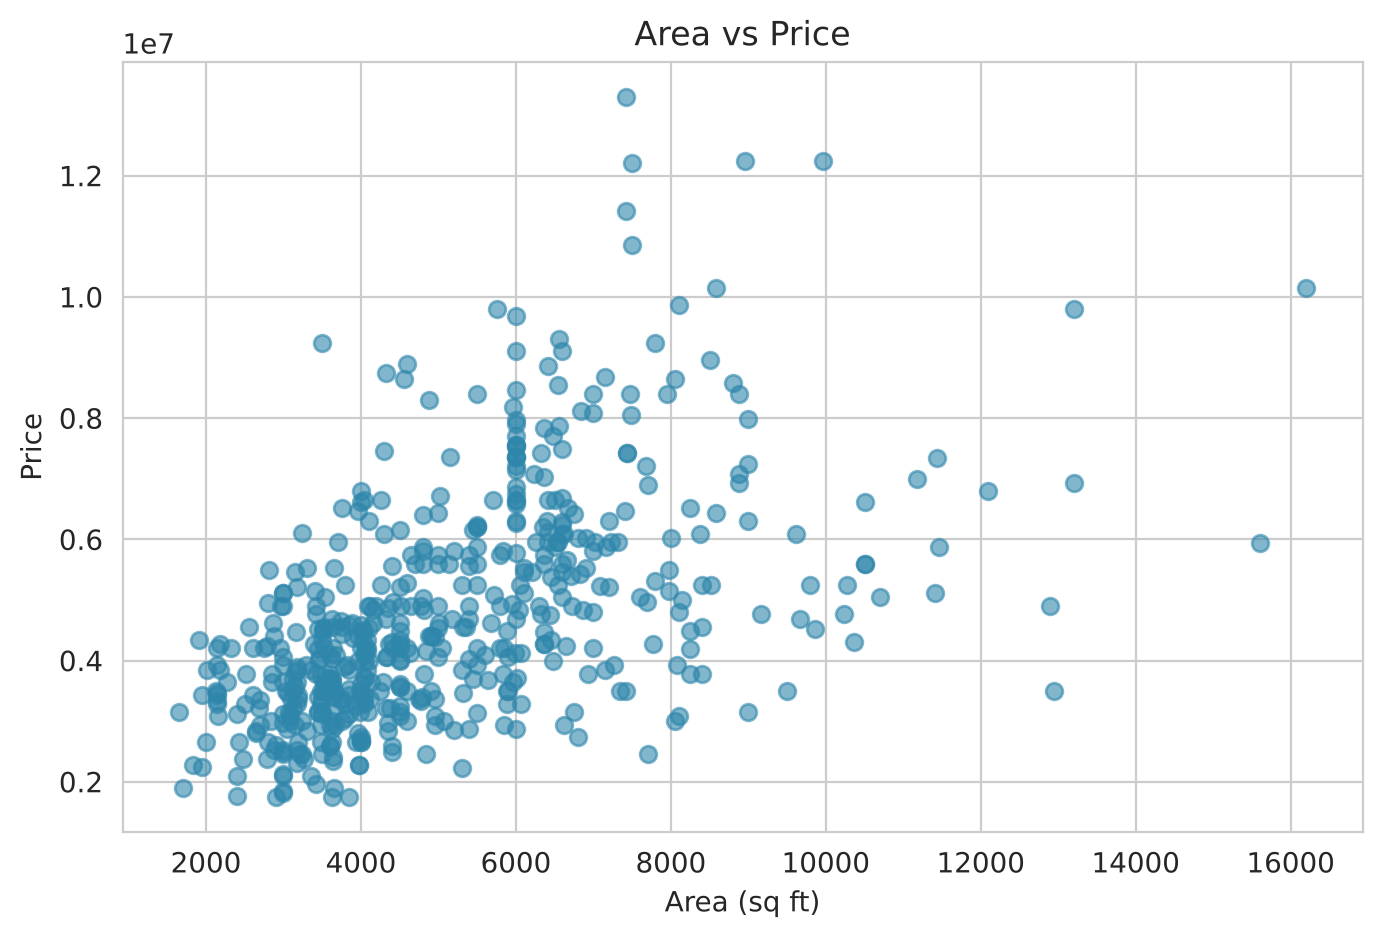

In [7]:
plt.scatter(df["area"], df["price"], alpha=0.6, color="#2E86AB")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price")
plt.title("Area vs Price")
plt.show()

**Observation:** Jaise jaise area barhta hai, price bhi generally upar jaati hai. Dots ek upar jaati hui line ki tarah phailay hue hain. Yahi wo pattern hai jo Linear Regression pakray ga!

Ab **correlation** dekhte hain. Correlation -1 se +1 ke beech hota hai:
- **+1 ke qareeb:** Dono sath barhte hain
- **0 ke qareeb:** Koi khaas relation nahi
- **-1 ke qareeb:** Ek barhe to doosra ghatay

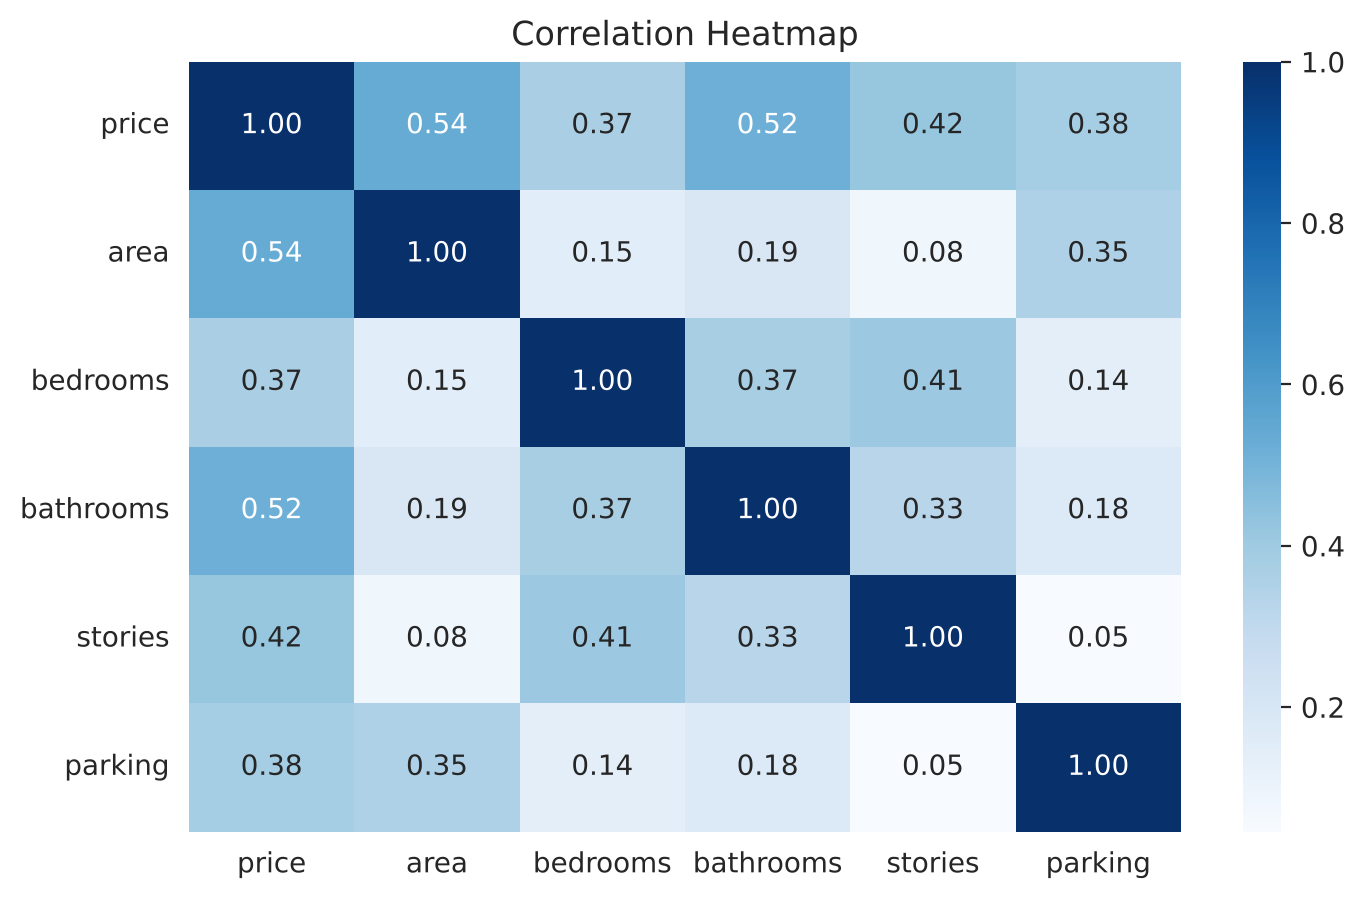

In [8]:
numeric_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]

sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

`price` wali row dekho. **area** aur **bathrooms** ka price se sab se strong relation hai. Matlab ye features price predict karne mein sab se zyada madad karein ge.

---
# 🅰️ Part A: Simple Linear Regression (sirf Area se Price)

Pehle sab se simple model banate hain: sirf **ek feature (area)** se **price** predict karna. Bilkul `y = mx + c` wala formula.

## Step 5: X aur y alag karna

- **X** = input (features). Double bracket `[["area"]]` isliay kyunke sklearn ko X table ki shakal mein chahiye
- **y** = output (target)

In [9]:
X_simple = df[["area"]]
y = df["price"]

print("X ki shape:", X_simple.shape)
print("y ki shape:", y.shape)

X ki shape: (545, 1)
y ki shape: (545,)


## Step 6: Train aur Test mein data baantna ✂️

Ye ML ka **bohat important concept** hai.

Socho exam ki tayyari. Agar teacher wohi sawal exam mein de jo class mein karwaye the, to pata hi nahi chalay ga ke student ne waqai samjha ya sirf ratta lagaya. Isliay:

- **Training data (80%):** Is se model seekhta hai (class ki practice)
- **Testing data (20%):** Ye model ne kabhi nahi dekha. Is se check karte hain model kitna acha hai (asal exam)

`random_state=42` ka matlab hai har baar same tareeqe se data bate, taa ke sab students ka result same aaye.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

print("Training gharon ki tadaad:", len(X_train))
print("Testing gharon ki tadaad:", len(X_test))

Training gharon ki tadaad: 436
Testing gharon ki tadaad: 109


## Step 7: Model banana aur train karna 🏋️

Sirf 2 lines!
- `LinearRegression()` khali model banata hai
- `.fit()` model ko training data dikha kar **sikhata** hai. Isi waqt model best line (m aur c) dhoondta hai

In [11]:
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

print("Model train ho gaya ✅")

Model train ho gaya ✅


## Step 8: Model ne kya seekha? (m aur c)

- `coef_` = **m (slope)**
- `intercept_` = **c (intercept)**

In [12]:
m = simple_model.coef_[0]
c = simple_model.intercept_

print(f"Slope (m): {m:,.2f}")
print(f"Intercept (c): {c:,.2f}")
print()
print(f"Model ka formula:  price = {m:,.2f} × area + {c:,.2f}")

Slope (m): 425.73
Intercept (c): 2,512,254.26

Model ka formula:  price = 425.73 × area + 2,512,254.26


**Iska matlab:** Area mein har **1 square foot** izafay se price lag bhag **m rupay** barh jaati hai (upar wali value). Ye model ne khud data se seekha, humne koi rule nahi diya! 🎉

## Step 9: Predictions karna 🔮

Ab model ko **test data** dete hain (jo usne kabhi nahi dekha) aur price predict karwate hain.

In [13]:
y_pred_simple = simple_model.predict(X_test)

# Pehle 5 gharon ki actual vs predicted price
comparison = pd.DataFrame({
    "Area": X_test["area"].values[:5],
    "Actual Price": y_test.values[:5],
    "Predicted Price": y_pred_simple[:5].round(0)
})
comparison

,Area,Actual Price,Predicted Price
0,5900,4060000,5024060.0
1,6500,6650000,5279498.0
2,4040,3710000,4232203.0
3,5000,6440000,4640903.0
4,3960,2800000,4198144.0


## Step 10: Best fit line ko graph pe dekhna

Blue dots asal ghar hain aur laal line model ki seekhi hui **best fit line** hai.

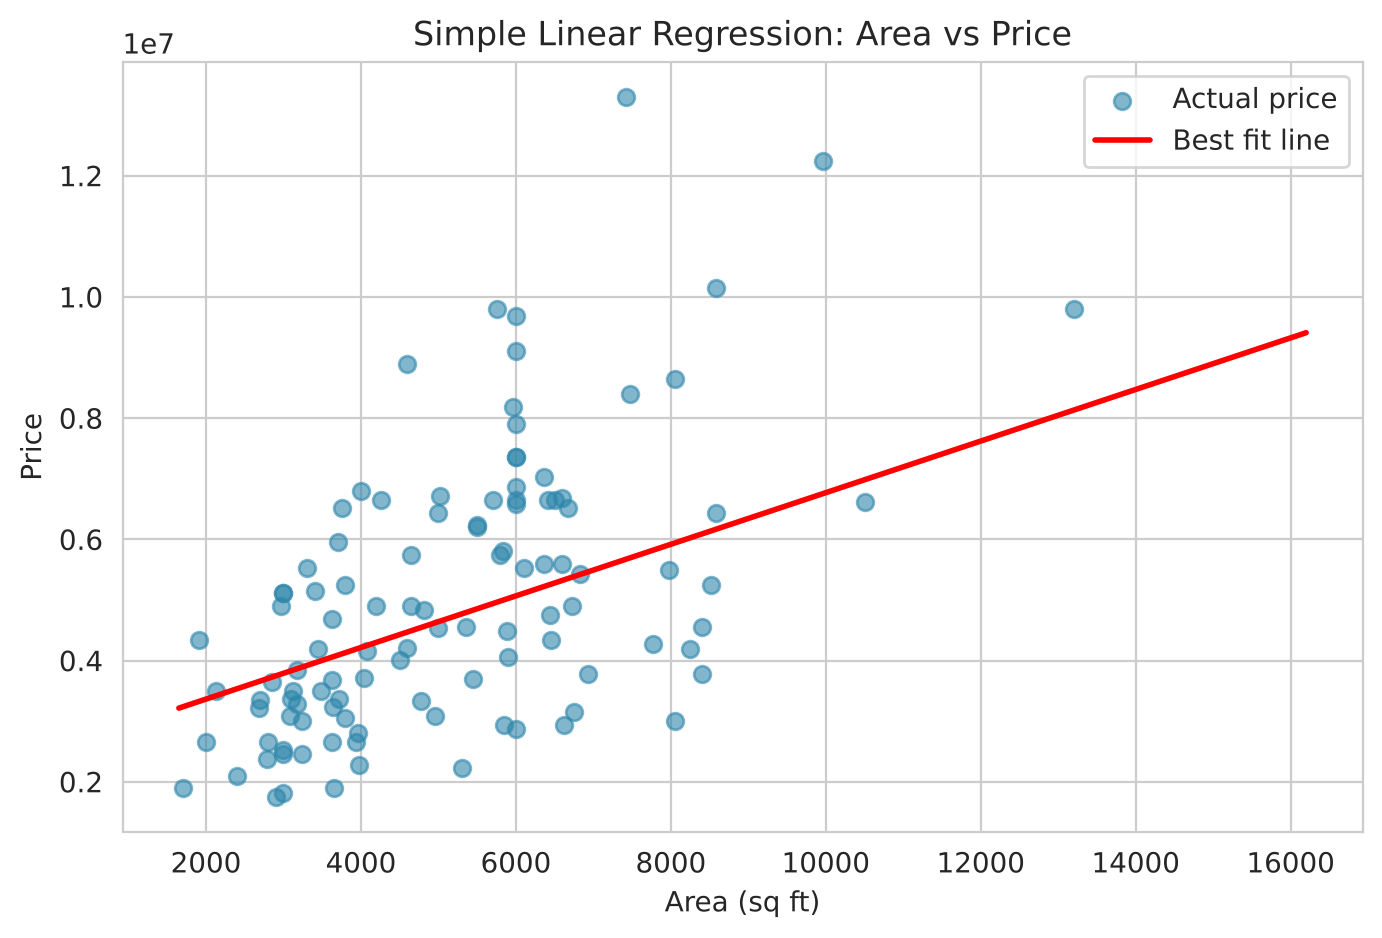

In [14]:
plt.scatter(X_test["area"], y_test, alpha=0.6, color="#2E86AB", label="Actual price")

line_x = pd.DataFrame({"area": np.linspace(df["area"].min(), df["area"].max(), 100)})
plt.plot(line_x["area"], simple_model.predict(line_x), color="red", linewidth=2, label="Best fit line")

plt.xlabel("Area (sq ft)")
plt.ylabel("Price")
plt.title("Simple Linear Regression: Area vs Price")
plt.legend()
plt.show()

## Step 11: Model kitna acha hai? (Evaluation) 📝

Model ko "marks" dene ke liay ye 3 cheezein dekhte hain:

- **MAE (Mean Absolute Error):** Average kitne rupay ka farq hai prediction mein. **Kam ho to acha**
- **RMSE (Root Mean Squared Error):** MAE jaisa, lekin bari ghaltiyon ko zyada saza deta hai. **Kam ho to acha**
- **R² Score:** 0 se 1 ke beech. Batata hai model price ke kitne hissay ko samajh paa raha hai. **1 ke qareeb ho to acha.** Jaise 0.30 matlab 30%

In [15]:
mae = mean_absolute_error(y_test, y_pred_simple)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_simple))
r2 = r2_score(y_test, y_pred_simple)

print(f"MAE  : {mae:,.0f}")
print(f"RMSE : {rmse:,.0f}")
print(f"R²   : {r2:.3f}")

MAE  : 1,474,748
RMSE : 1,917,104
R²   : 0.273


**Result samjho:** R² kaafi kam hai. Iska matlab sirf **area** se price ka poora andaza nahi lagta. Real life mein bhi ghar ki price sirf size se nahi banti. Location, AC, bathrooms, parking sab matter karte hain.

To chalo model ko **zyada features** dete hain! 🚀

---
# 🅱️ Part B: Multiple Linear Regression (sab features se Price)

## Step 12: Data ko model ke liay tayyar karna (Preprocessing) 🧹

Machine Learning model sirf **numbers** samajhta hai, "yes" ya "furnished" jaise words nahi. Isliay text ko numbers mein badalna parta hai.

**1) Yes/No columns:** `yes` ko **1** aur `no` ko **0** bana dete hain.

In [16]:
data = df.copy()   # original data ko kharab nahi karna, copy pe kaam karein ge

yes_no_cols = ["mainroad", "guestroom", "basement",
               "hotwaterheating", "airconditioning", "prefarea"]

for col in yes_no_cols:
    data[col] = data[col].map({"yes": 1, "no": 0})

data[yes_no_cols].head()

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea
0,1,0,0,0,1,1
1,1,0,0,0,1,0
2,1,0,1,0,0,1
3,1,0,1,0,1,1
4,1,1,1,0,1,0


**2) furnishingstatus column:** Isme 3 values hain. Hum inhe 1, 2, 3 nahi bana sakte kyunke model samjhe ga "3 waala 1 se teen guna behtar hai", jo ghalat hai.

Isliay **One-Hot Encoding** karte hain: har option ka alag column banta hai jisme 1 ya 0 hota hai. `drop_first=True` ek column hata deta hai kyunke baqi do se wo khud pata chal jata hai (agar dono 0 hain to ghar furnished hai).

In [17]:
data = pd.get_dummies(data, columns=["furnishingstatus"], drop_first=True, dtype=int)

data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


Ab saara data numbers mein hai. ✅

## Step 13: X aur y banana (is baar sab features ke sath)

`drop("price", axis=1)` ka matlab hai price ke ilawa baqi saare columns X mein daal do.

In [18]:
X = data.drop("price", axis=1)
y = data["price"]

print("Features jo model use kare ga:")
print(list(X.columns))

Features jo model use kare ga:
['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


## Step 14: Train/Test split, training, aur prediction

Wohi steps jo Part A mein kiay the, bas is baar X mein zyada columns hain.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

y_pred_multi = multi_model.predict(X_test)

print("Multiple Linear Regression model train ho gaya ✅")

Multiple Linear Regression model train ho gaya ✅


## Step 15: Evaluation aur dono models ka muqabla 🥊

In [20]:
mae_m = mean_absolute_error(y_test, y_pred_multi)
rmse_m = np.sqrt(mean_squared_error(y_test, y_pred_multi))
r2_m = r2_score(y_test, y_pred_multi)

results = pd.DataFrame({
    "Model": ["Simple (sirf area)", "Multiple (sab features)"],
    "MAE": [round(mae), round(mae_m)],
    "RMSE": [round(rmse), round(rmse_m)],
    "R² Score": [round(r2, 3), round(r2_m, 3)]
})
results

,Model,MAE,RMSE,R² Score
0,Simple (sirf area),1474748,1917104,0.273
1,Multiple (sab features),970043,1324507,0.653


**Zabardast! 🎉** Zyada features dene se R² score kaafi barh gaya aur error kam ho gaya. Matlab ab model price ko kahin behtar samajh raha hai.

**Lesson:** Model utna hi acha hota hai jitna acha aur poora data usay diya jaye.

## Step 16: Kaunsa feature price pe kitna asar daalta hai? 🔎

Har feature ka apna coefficient (m) hota hai. Ye batata hai ke baqi sab same rakh kar, us feature ke 1 unit barhne se price kitni badalti hai.

- **Positive value:** Price barhati hai
- **Negative value:** Price ghatati hai

In [21]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": multi_model.coef_.round(0)
}).sort_values("Coefficient", ascending=False)

coef_df

,Feature,Coefficient
2,bathrooms,1094445.0
8,airconditioning,791427.0
7,hotwaterheating,684650.0
10,prefarea,629891.0
3,stories,407477.0
6,basement,390251.0
4,mainroad,367920.0
5,guestroom,231610.0
9,parking,224842.0
1,bedrooms,76779.0


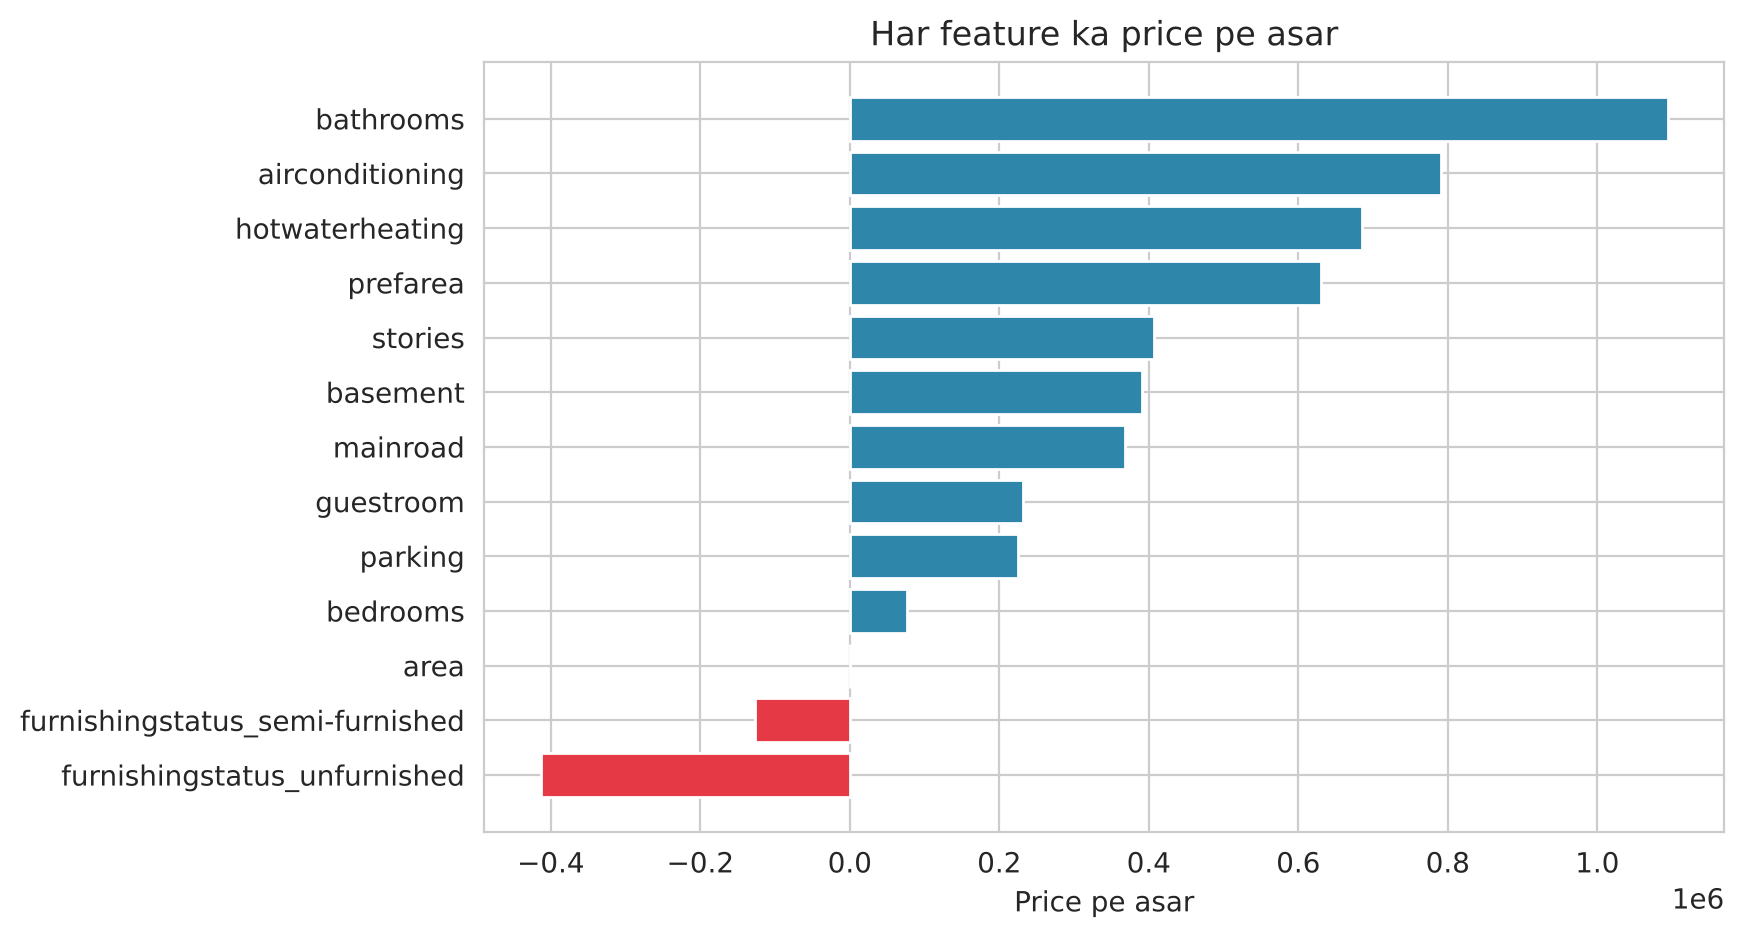

In [22]:
colors = ["#2E86AB" if v > 0 else "#E63946" for v in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.xlabel("Price pe asar")
plt.title("Har feature ka price pe asar")
plt.gca().invert_yaxis()
plt.show()

**Samjho:** Misal ke taur pe `bathrooms` ka coefficient batata hai ke ek extra bathroom se ghar ki price lag bhag itni barh jaati hai. `airconditioning` aur `prefarea` (achi location) bhi price ko kaafi upar le jaate hain.

> ⚠️ Note: `area` ka coefficient chhota lagta hai kyunke wo **1 square foot** ka asar hai, jabke bathroom ka asar **1 poore bathroom** ka hai. Units alag hain, isliay seedha compare na karein.

## Step 17: Actual vs Predicted graph

Agar model perfect hota to saare dots laal dotted line pe hote. Jitna line ke qareeb, utna acha.

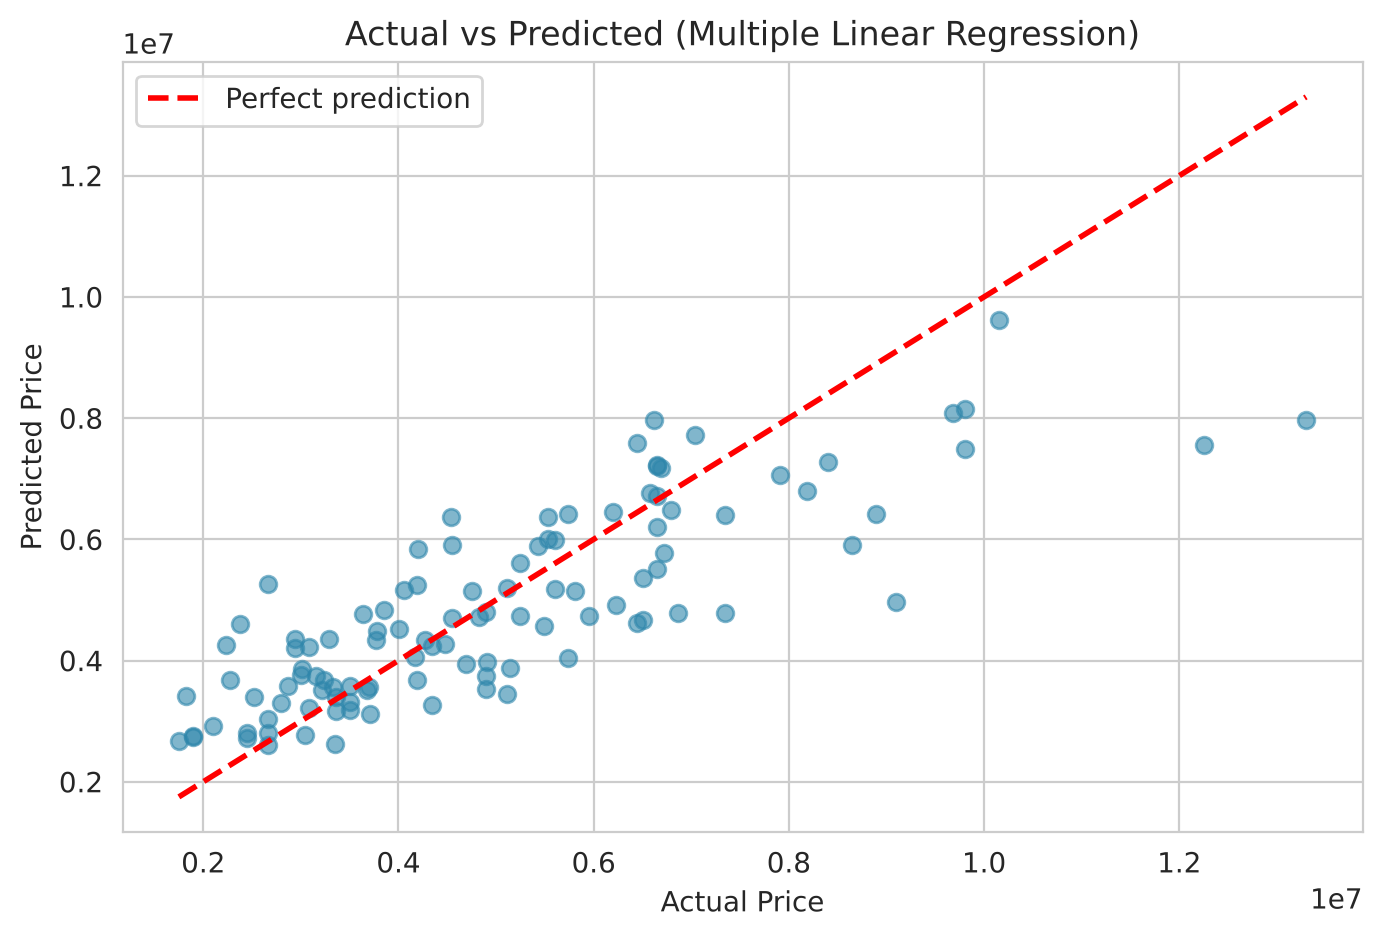

In [23]:
plt.scatter(y_test, y_pred_multi, alpha=0.6, color="#2E86AB")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted (Multiple Linear Regression)")
plt.legend()
plt.show()

---
## Step 18: Naye ghar ki price predict karo! 🏡

Ab asal maza. Ek naya ghar banao jo dataset mein hai hi nahi, aur model se uski price poocho. Values badal badal kar khud try karo!

In [24]:
new_house = pd.DataFrame([{
    "area": 6000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": 1,          # 1 = yes, 0 = no
    "guestroom": 0,
    "basement": 1,
    "hotwaterheating": 0,
    "airconditioning": 1,
    "parking": 2,
    "prefarea": 1,
    "furnishingstatus_semi-furnished": 1,   # semi-furnished hai
    "furnishingstatus_unfurnished": 0
}])

# Columns ka order bilkul training wala hona chahiye
new_house = new_house[X.columns]

predicted_price = multi_model.predict(new_house)[0]
print(f"Is ghar ki andazan price: {predicted_price:,.0f}")

Is ghar ki andazan price: 7,412,314


---
## 📚 Summary: Aaj humne kya seekha

1. **Machine Learning:** Computer ko rules ki jagah data do, wo khud pattern seekh le ga
2. **Supervised Learning:** Data ke sath sahi jawab (label) bhi diya jata hai. Iski 2 types hain: Regression (number) aur Classification (category)
3. **Linear Regression:** Data mein best seedhi line fit karta hai (`y = mx + c`)
4. **ML ka workflow** jo har project mein same rehta hai:
   - Data load karo ➜ Explore karo ➜ Saaf karo (preprocessing) ➜ X aur y alag karo ➜ Train/Test split ➜ `.fit()` ➜ `.predict()` ➜ Evaluate (MAE, RMSE, R²)
5. **Zyada aur sahi features** dene se model behtar hota hai

---
## ✍️ Homework / Practice

1. Simple Linear Regression ko `area` ki jagah `bathrooms` ke sath chalao. R² score pehle se behtar aaya ya bura?
2. `test_size=0.2` ko `0.3` kar ke dekho. Results mein kya farq aaya?
3. Step 18 mein apne khwabon ka ghar banao 😄 aur uski price predict karo. Phir AC ko 0 kar ke dekho price kitni girti hai
4. Multiple model se `furnishingstatus` wale columns hata kar train karo. Kya R² pe koi khaas farq para?

**Shabash! Aapne apna pehla Machine Learning model bana liya. 🎓**